**# Laboratório 1: Perceptron — RNA simples e linear**

*Objetivos:*
- Entender modelo linear com ativação ReLU/sinal.
- Ajuste de pesos via descida do gradiente.
- Visualizar separação linear em dados 2D.

*Prática:*

- Implementar perceptron simples com Dense(1) camada.
- Treinar em dados sintéticos (ex: pontos 2D separáveis).
- Explorar taxa de aprendizado, número de épocas e função de ativação.
- Visualizar fronteira de decisão.

*Conceitos fixados:*
- Pesos e bias como parâmetros ajustáveis.
- Função de ativação limita linearidade.
- Limitação: incapaz de resolver problemas não linearmente separáveis (XOR).

*-----*
- O Perceptron é uma rede neural de uma camada, capaz de separar dados linearmente. Os parâmetros principais são os pesos, bias e a função de ativação.

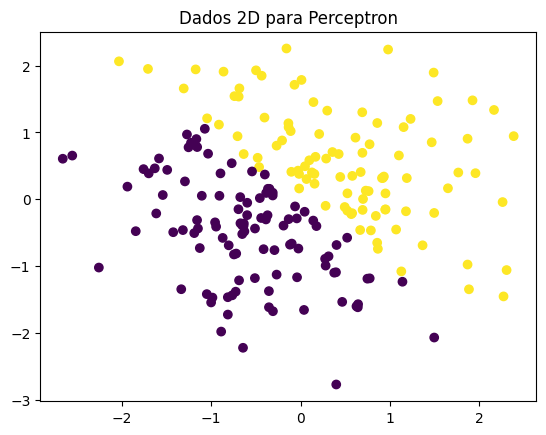

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1132 - loss: 1.4797 
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0646 - loss: 1.5201    
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0835 - loss: 1.4760
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0694 - loss: 1.4684
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.0805 - loss: 1.3881
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.0811 - loss: 1.4106
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0848 - loss: 1.3728
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.0655 - loss: 1.3580
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0708 - loss: 1.3662
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0753 - loss: 1.2710
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0889 - loss: 1.2533
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0602 - loss: 1.2

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Gerando dados lineares separáveis 2D
np.random.seed(0)
X = np.random.randn(200, 2)  # 200 amostras, 2 features (dimensão)
y = (X[:, 0] + X[:, 1] > 0).astype(int)  # rótulo 1 se soma > 0, senão 0

# Visualização dos dados
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title('Dados 2D para Perceptron')
plt.show()

# Construção do Perceptron - modelo com 1 camada Dense
model = Sequential()
# Dense(1) = saída única, input_dim=2 (duas features)
# ativação sigmoid para saída probabilística (0 a 1)
model.add(Dense(1, input_dim=2, activation='sigmoid'))

# Compile:
# - Otimizador: SGD (gradiente descendente simples)
# - Loss: binary_crossentropy (problema binário)
# - Métrica: accuracy (acurácia)
model.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

# Treinando o modelo
# batch_size padrão = 32, epochs = número de iterações nos dados
history = model.fit(X, y, epochs=50, verbose=1)

# Avaliando o modelo nos mesmos dados
loss, acc = model.evaluate(X, y)
print(f"Acurácia: {acc:.2f}")

# Explicação importante:
# - SGD atualiza pesos após cada batch (padrão 32)
# - Epoch: ciclo completo pelo conjunto de dados
# - Ativação sigmoid: função logística que transforma valor em probabilidade
# - Bias (interna): permite deslocar hiperplano de decisão


- Teste diferentes funções de ativação (relu, sigmoid).

- Observe que o Perceptron só separa dados linearmente.